In [1]:
# Cell 1: Set paths and processing parameters.
from pathlib import Path
import sys

# Run from implement/ or its parent project directory.
IMPLEMENT_DIR = Path.cwd().resolve()
if not (IMPLEMENT_DIR / "crystal_pipeline.py").is_file():
    IMPLEMENT_DIR = IMPLEMENT_DIR / "implement"
if not (IMPLEMENT_DIR / "crystal_pipeline.py").is_file():
    raise FileNotFoundError("Start Jupyter from implement/ or its parent directory.")
sys.path.insert(0, str(IMPLEMENT_DIR))
PROJECT_ROOT = IMPLEMENT_DIR.parent
INPUT_DIR = IMPLEMENT_DIR / "data"
RUN_DIR = IMPLEMENT_DIR / "outputs" / "trial_step1_001"  # Use a new name for different settings.
MODEL_DIR = PROJECT_ROOT / "training/output/step1_only_001/export/implement_bundle/models"
COLOR_REFERENCE_PATH = MODEL_DIR / "rf_step1.pkl"
CONFIG = {
    "data_dir": "data/mag500",
    "target_plates": {"old": ["pl01", "pl02", "pl04"], "new": ["pl01", "pl02", "pl04"]},
    "images_per_plate": 3,
    "crop": {"top": 60, "bottom": 100, "left": 60, "right": 100},
    "n_segments": 300, "compactness": 10.0,
}
print(f"Project: {PROJECT_ROOT}\nRun: {RUN_DIR}")

Project: /home/kmanabe2403/dune
Run: /home/kmanabe2403/dune/implement/outputs/trial_step1_001


In [2]:
# Cell 2: Save selected image paths and settings (no image loading).
# Re-running Cells 2-4 overwrites outputs. Use a new run name for a separate experiment.
from crystal_pipeline import prepare_run

prepare_run(PROJECT_ROOT, RUN_DIR, CONFIG)

Selected images: 18 | Metadata: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/metadata


In [3]:
# Cell 3: Crop images, compute SLIC segments, and save per-image Lab means.
from crystal_preprocessing import run_preprocessing

run_preprocessing(PROJECT_ROOT, RUN_DIR)

[1/18] 20260807_095058: 224 superpixels
[2/18] 20260807_095154: 252 superpixels
[3/18] 20260807_095234: 211 superpixels
[4/18] 20260807_100728: 243 superpixels
[5/18] 20260807_100809: 250 superpixels
[6/18] 20260807_100913: 288 superpixels
[7/18] 20260806_135656: 211 superpixels
[8/18] 20260806_135735: 207 superpixels
[9/18] 20260806_135900: 220 superpixels
[10/18] 20260806_130825: 294 superpixels
[11/18] 20260806_130921: 290 superpixels
[12/18] 20260806_131007: 300 superpixels
[13/18] 20260806_131657: 177 superpixels
[14/18] 20260806_131743: 197 superpixels
[15/18] 20260806_131837: 190 superpixels
[16/18] 20260806_132552: 209 superpixels
[17/18] 20260806_132631: 219 superpixels
[18/18] 20260806_132708: 207 superpixels
Output: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/preprocessing


In [4]:
# Cell 4: Save pixel-Lab corrections using the RF model's own reference.
from crystal_preprocessing import run_color_correction

run_color_correction(RUN_DIR, COLOR_REFERENCE_PATH)

[1/18] image_0000: saved
[2/18] image_0001: saved
[3/18] image_0002: saved
[4/18] image_0003: saved
[5/18] image_0004: saved
[6/18] image_0005: saved
[7/18] image_0006: saved
[8/18] image_0007: saved
[9/18] image_0008: saved
[10/18] image_0009: saved
[11/18] image_0010: saved
[12/18] image_0011: saved
[13/18] image_0012: saved
[14/18] image_0013: saved
[15/18] image_0014: saved
[16/18] image_0015: saved
[17/18] image_0016: saved
[18/18] image_0017: saved
Output: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/color_correction


In [5]:
# Cell 5: Calculate and save the original 18 RF features, one image at a time.
from crystal_features import run_feature_extraction

run_feature_extraction(RUN_DIR)

[1/18] image_0000: 224 superpixels, 18 features
[2/18] image_0001: 252 superpixels, 18 features
[3/18] image_0002: 211 superpixels, 18 features
[4/18] image_0003: 243 superpixels, 18 features
[5/18] image_0004: 250 superpixels, 18 features
[6/18] image_0005: 288 superpixels, 18 features
[7/18] image_0006: 211 superpixels, 18 features
[8/18] image_0007: 207 superpixels, 18 features
[9/18] image_0008: 220 superpixels, 18 features
[10/18] image_0009: 294 superpixels, 18 features
[11/18] image_0010: 290 superpixels, 18 features
[12/18] image_0011: 300 superpixels, 18 features
[13/18] image_0012: 177 superpixels, 18 features
[14/18] image_0013: 197 superpixels, 18 features
[15/18] image_0014: 190 superpixels, 18 features
[16/18] image_0015: 209 superpixels, 18 features
[17/18] image_0016: 219 superpixels, 18 features
[18/18] image_0017: 207 superpixels, 18 features
Output: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/features


In [6]:
# Cell 6: Group superpixels by standardized features using PCA and GMM.
# Cluster IDs are local to each image; they are not crystal class labels.
from crystal_gmm import run_gmm

run_gmm(RUN_DIR, n_components=3, pca_components=15, probability_cut=0.90)

[1/18] image_0000: 224 superpixels, 222 high confidence
[2/18] image_0001: 252 superpixels, 241 high confidence
[3/18] image_0002: 211 superpixels, 203 high confidence
[4/18] image_0003: 243 superpixels, 228 high confidence
[5/18] image_0004: 250 superpixels, 236 high confidence
[6/18] image_0005: 288 superpixels, 278 high confidence
[7/18] image_0006: 211 superpixels, 194 high confidence
[8/18] image_0007: 207 superpixels, 201 high confidence
[9/18] image_0008: 220 superpixels, 212 high confidence
[10/18] image_0009: 294 superpixels, 263 high confidence
[11/18] image_0010: 290 superpixels, 262 high confidence
[12/18] image_0011: 300 superpixels, 269 high confidence
[13/18] image_0012: 177 superpixels, 173 high confidence
[14/18] image_0013: 197 superpixels, 182 high confidence
[15/18] image_0014: 190 superpixels, 183 high confidence
[16/18] image_0015: 209 superpixels, 189 high confidence
[17/18] image_0016: 219 superpixels, 206 high confidence
[18/18] image_0017: 207 superpixels, 186

In [7]:
# Cell 7: Classify GMM clusters and save crystal class area ratios.
from crystal_rf import run_rf_classification

model_dir = MODEL_DIR
stage2_paths = {}  # Five-class step1 only.
stage3_paths = {}
run_rf_classification(RUN_DIR, model_dir / "rf_step1.pkl", stage2_paths, stage3_paths)

[1/18] image_0000: 3 clusters classified
[2/18] image_0001: 3 clusters classified
[3/18] image_0002: 3 clusters classified
[4/18] image_0003: 3 clusters classified
[5/18] image_0004: 3 clusters classified
[6/18] image_0005: 3 clusters classified
[7/18] image_0006: 3 clusters classified
[8/18] image_0007: 3 clusters classified
[9/18] image_0008: 3 clusters classified
[10/18] image_0009: 3 clusters classified
[11/18] image_0010: 3 clusters classified
[12/18] image_0011: 3 clusters classified
[13/18] image_0012: 3 clusters classified
[14/18] image_0013: 3 clusters classified
[15/18] image_0014: 3 clusters classified
[16/18] image_0015: 3 clusters classified
[17/18] image_0016: 3 clusters classified
[18/18] image_0017: 3 clusters classified
Output: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/rf


In [8]:
# Cell 8: Create the manual correction table; keep existing edits on rerun.
from crystal_review import prepare_corrections

CORRECTIONS_PATH = prepare_corrections(RUN_DIR)

Saved 54 clusters: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/review/cluster_corrections.csv
Fill new_class only for clusters you want to change; leave other rows blank.
Edits will be applied in a later cell. RF predictions are unchanged.


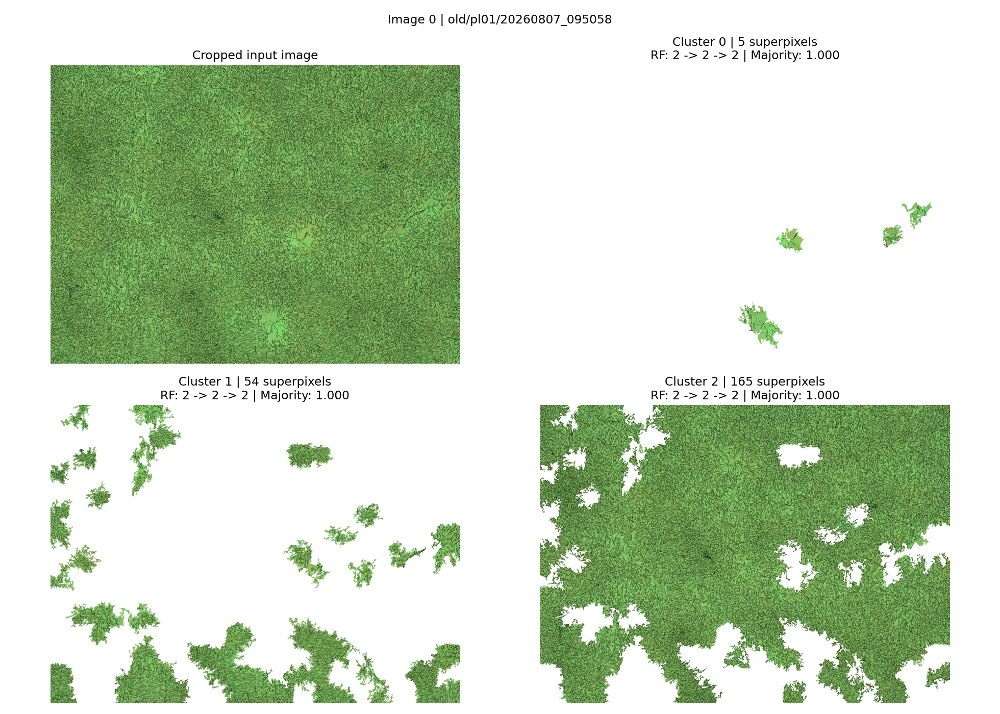

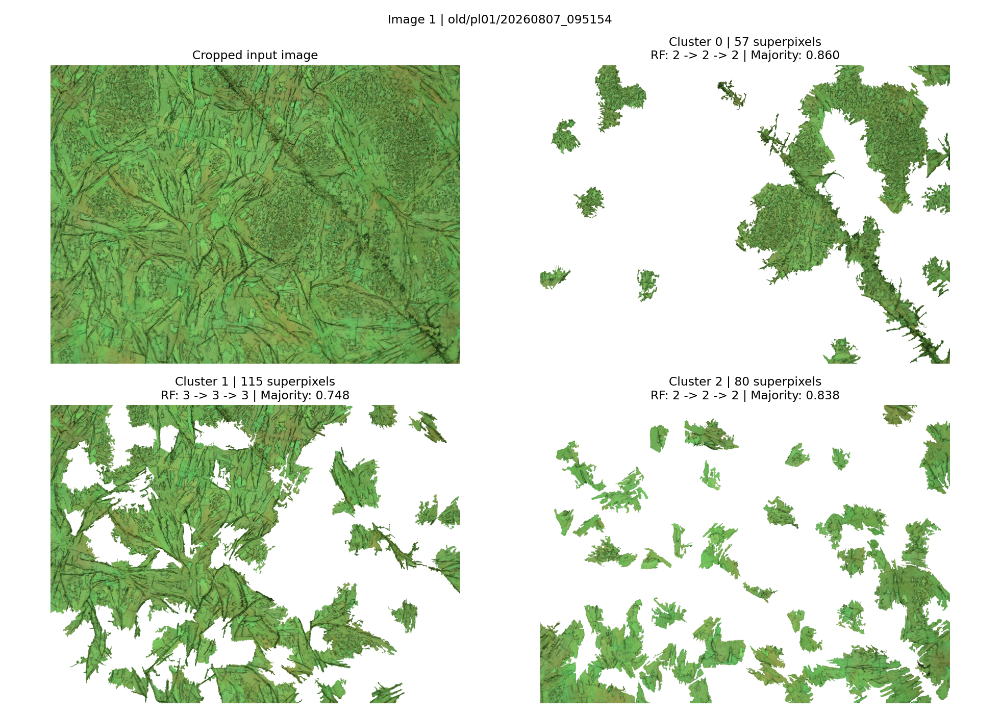

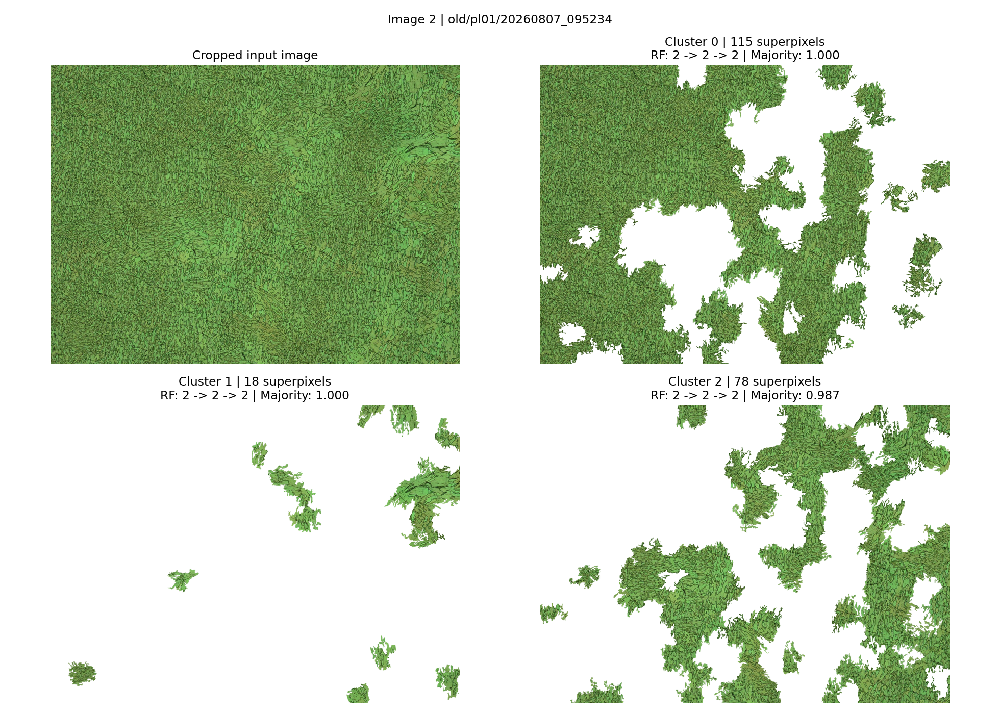

Saved: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/review/figures/image_0000.png
Saved: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/review/figures/image_0001.png
Saved: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/review/figures/image_0002.png


In [9]:
# Cell 9: Inspect the original image and its GMM clusters for one plate.
# Use image_id and cluster_id to find the matching row in cluster_corrections.csv.
from crystal_review import show_clusters

show_clusters(RUN_DIR, group="old", plate="pl01")

In [10]:
# Cell 10: Apply nonblank new_class entries and recalculate areas.
# Original RF outputs are preserved; reruns overwrite rf_corrected/.
from crystal_corrections import apply_manual_corrections

apply_manual_corrections(RUN_DIR)

[1/18] image_0000: 0 manual assignments
[2/18] image_0001: 0 manual assignments
[3/18] image_0002: 0 manual assignments
[4/18] image_0003: 0 manual assignments
[5/18] image_0004: 0 manual assignments
[6/18] image_0005: 0 manual assignments
[7/18] image_0006: 0 manual assignments
[8/18] image_0007: 0 manual assignments
[9/18] image_0008: 0 manual assignments
[10/18] image_0009: 0 manual assignments
[11/18] image_0010: 0 manual assignments
[12/18] image_0011: 0 manual assignments
[13/18] image_0012: 0 manual assignments
[14/18] image_0013: 0 manual assignments
[15/18] image_0014: 0 manual assignments
[16/18] image_0015: 0 manual assignments
[17/18] image_0016: 0 manual assignments
[18/18] image_0017: 0 manual assignments
Applied 0 assignments. Output: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/rf_corrected


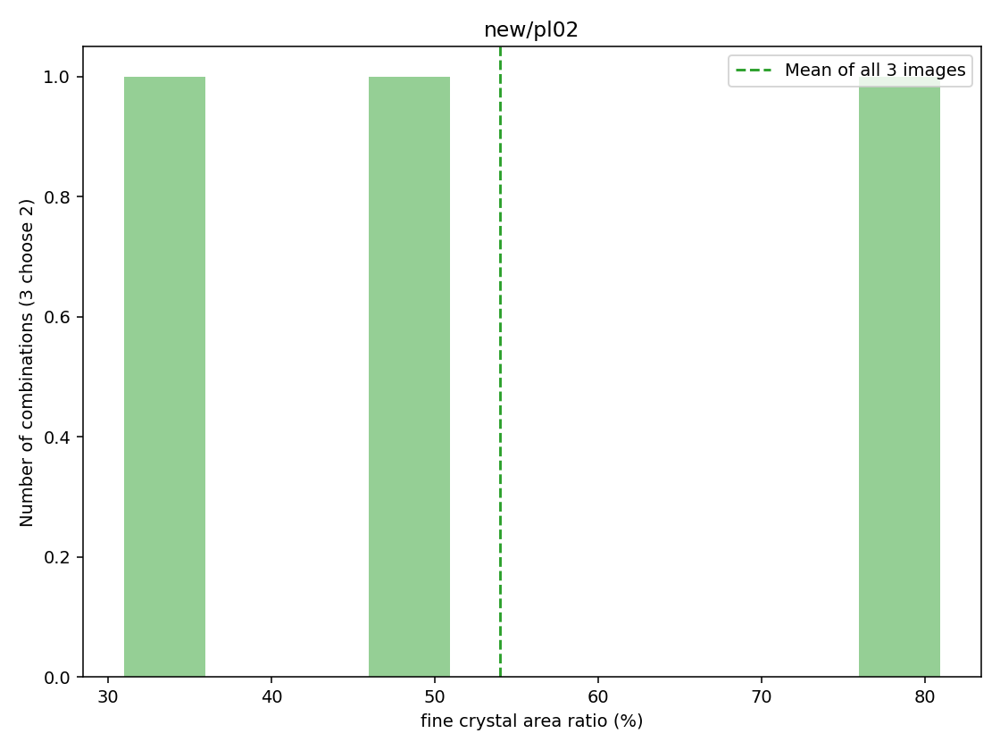

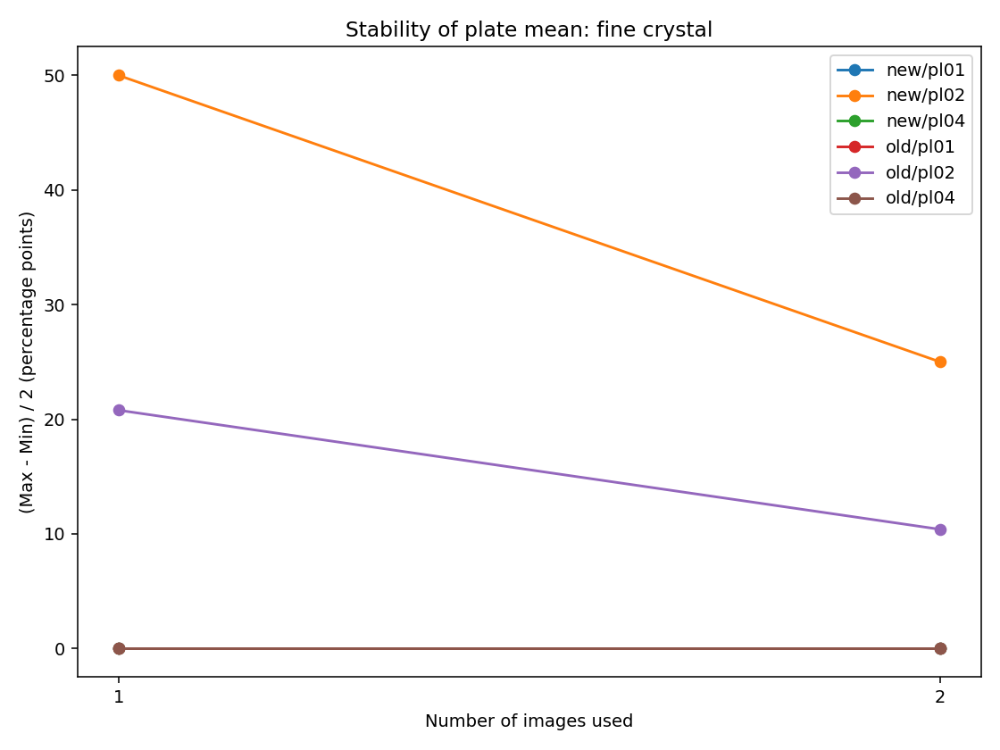

Area columns: ['class_0_area_ratio']
new/pl02: 3 images, choose 2, 3 combinations; half range: 25.000 percentage points
Output: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/rf_corrected/sampling/fine_crystal


In [11]:
# Cell 11: Sampling systematic error — histogram and stability plot.
from crystal_sampling import analyze_sampling

AREA_CSV = RUN_DIR / "rf_corrected" / "area_ratios.csv"
# Parent label 0 includes both 0 and any 0_* subclasses present in the results.
# Current data: 3 images per plate, so choose 2; set n_use=4 after processing 8 images.
analyze_sampling(AREA_CSV, target_labels=["0"], class_name="fine crystal", group="new", plate="pl02", n_use=2, max_error=None)

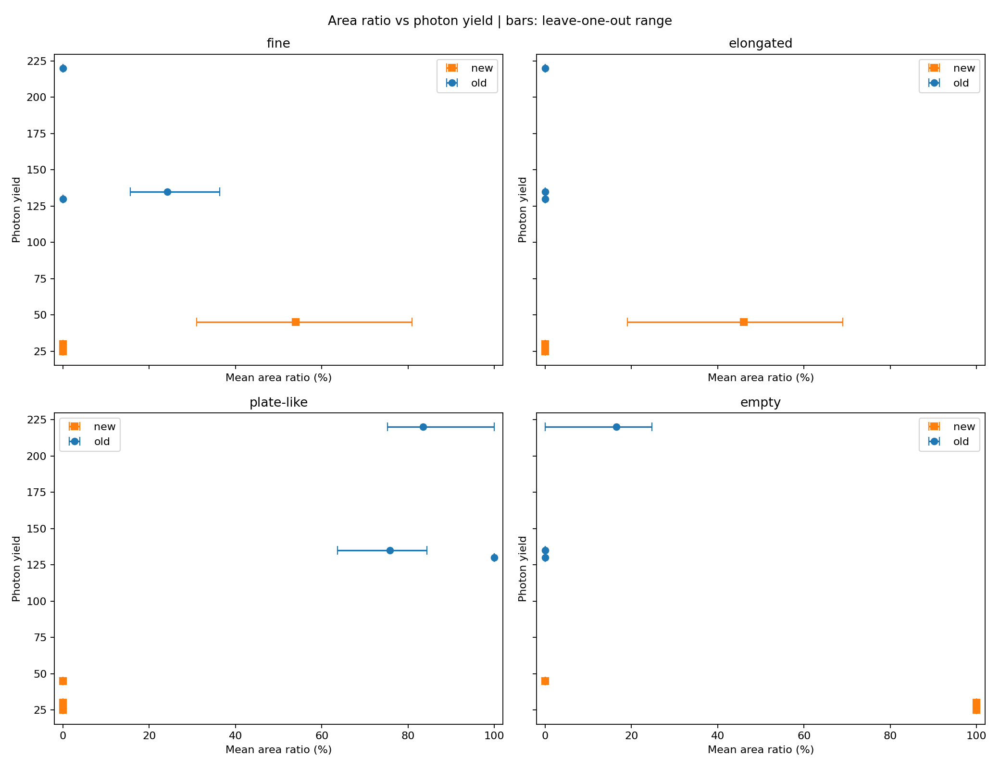

Saved 24 plate/category results: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/rf_corrected/photon_yield


In [12]:
# Cell 12: Plot four area categories vs photon yield in a single 2-by-2 figure.
# Bars show leave-one-out ranges for plates with at least two images.
from crystal_photon import plot_area_photon

CLASS_GROUPS = {
    "fine": ["0"], "elongated": ["1"],
    "plate-like": ["2"], "empty": ["3"],
}
AREA_CSV = RUN_DIR / "rf_corrected" / "area_ratios.csv"
plot_area_photon(AREA_CSV, INPUT_DIR / "tables" / "photon_yield.csv", CLASS_GROUPS, min_area=0.0)

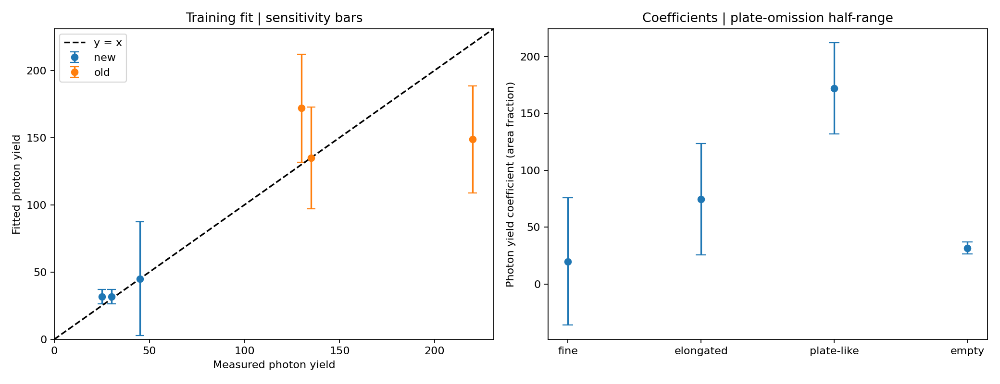

  category  coefficient  loo_half_range      loo_min    loo_max
      fine    19.805460       56.002128 5.579870e-21 112.004255
 elongated    74.541121       48.881717 0.000000e+00  97.763434
plate-like   171.847366       40.144198 1.345060e+02 214.794379
     empty    31.643839        5.351555 2.750000e+01  38.203109
Training R2: 0.7708 | Training RMSE: 33.8770 | Leave-one-plate-out RMSE: 56.6372
Output: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/rf_corrected/photon_yield/model


In [13]:
# Cell 13: Fit the bounded weighted photon-yield model for the four area categories.
# Fit scores use training plates; plate-omission results are saved separately.
from crystal_photon_model import fit_photon_model

PLATE_CSV = AREA_CSV.parent / "photon_yield" / "plate_area_photon.csv"
fit_photon_model(PLATE_CSV, categories=list(CLASS_GROUPS), bounds=(0, 500))

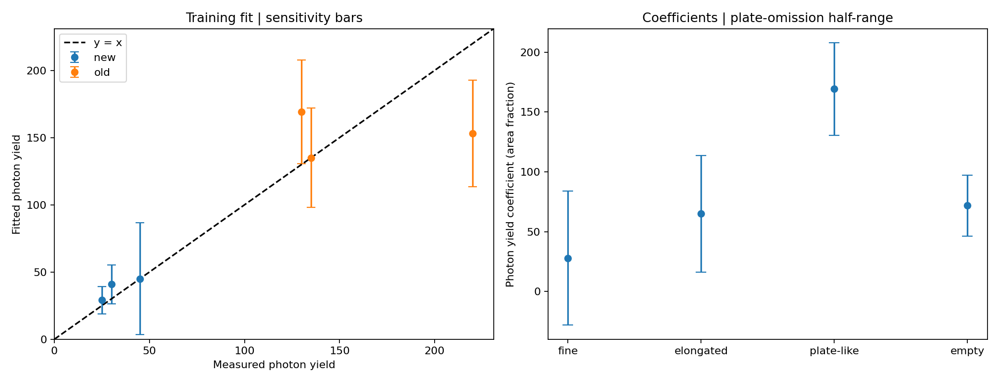

Coverage: 107 images, 18 plates; skipped settings: 131
Coverage applied to 3/6 plates; missing coverage uses factor 1.
  category  coefficient  loo_half_range      loo_min    loo_max
      fine    27.978707       56.002128 2.322407e-27 112.004255
 elongated    64.957819       48.881717 0.000000e+00  97.763434
plate-like   169.232983       38.590724 1.345060e+02 211.687431
     empty    71.802126       25.421099 5.582834e+01 106.670534
Training R2: 0.7954 | Training RMSE: 32.0007 | Leave-one-plate-out RMSE: 55.1773
Output: /home/kmanabe2403/dune/implement/outputs/trial_step1_001/rf_corrected/photon_yield/model_coverage


In [14]:
# Cell 14: Fit the photon-yield model with empty area multiplied by coverage.
# Use cluster-based coverage means; missing plates retain their uncorrected empty area.
# Coverage variability is saved but not included in model sensitivity bars.
from crystal_coverage import fit_coverage_model

fit_coverage_model(PLATE_CSV, INPUT_DIR / "tables" / "coverage_settings.csv", INPUT_DIR / "tables" / "coverage_result.csv", categories=list(CLASS_GROUPS), bounds=(0, 500))